# 优化版：客户聚类改进实验

> 针对 `analysis.ipynb` 11.8「局限性与改进方向」中的 5 个改进点逐项实验、量化对比：
> 1. **特征扩展**：独特商品数 / 平均客单价 / 订单间隔标准差 / 退货率
> 2. **极端值处理**：Monetary Winsorize（99 分位截断）稳健性检验
> 3. **K 再验证**：K=3/4/5/6 画像与业务解释力对比
> 4. **业务验证**：RFM 经典 5 档分箱交叉验证
> 5. **特征相关性（可选）**：相关矩阵 + PCA 降维对比

数据口径与 `analysis.ipynb` 完全一致（541,909 → 397,884 → 392,692 / 4,338 客户 / 18,532 订单）。

## 0. 环境配置

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang HK", "Hiragino Sans GB", "Heiti TC", "Songti SC"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")  # 打印浮点数统一千分位+2位小数（与 analysis.ipynb 一致）

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)

## 1. 数据加载与清洗（口径与原 notebook 一致）

In [2]:
DATA = "../data/OnlineRetail.csv"
df_raw = pd.read_csv(DATA, encoding="latin-1")
df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"])
# 退货/取消标记：负 Quantity 或 C 开头（取消单），供后续退货率特征使用
df_raw["is_return"] = (df_raw["Quantity"] < 0) | df_raw["InvoiceNo"].astype(str).str.startswith("C")
print(f"原始行数: {df_raw.shape[0]:,}")

# 清洗四步：剔 CustomerID 缺失 → 剔非正 Quantity/UnitPrice → 剔 C 单 → 去重
df = df_raw[df_raw["CustomerID"].notna()]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df.drop_duplicates()
print(f"清洗后: {df.shape[0]:,} 行 | {df['CustomerID'].nunique():,} 个客户 | {df['InvoiceNo'].nunique():,} 个订单")
df["Amount"] = df["Quantity"] * df["UnitPrice"]

原始行数: 541,909
清洗后: 392,692 行 | 4,338 个客户 | 18,532 个订单


## 2. 基础 RFM 与特征扩展

In [3]:
REF_DATE = pd.Timestamp("2011-12-09")
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (REF_DATE - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Amount", "sum"),
)
print(f"RFM 客户数: {len(rfm):,}")
rfm.describe()  # 完整统计摘要（count/mean/std/min/分位数/max），与 analysis.ipynb 输出格式一致

RFM 客户数: 4,338


,Recency,Frequency,Monetary
count,"4,338.00","4,338.00","4,338.00"
mean,92.06,4.27,"2,048.69"
std,100.01,7.70,"8,985.23"
min,0.00,1.00,3.75
25%,17.00,1.00,306.48
50%,50.00,2.00,668.57
75%,141.75,5.00,"1,660.60"
max,373.00,209.00,"280,206.02"


In [4]:
# ① 独特商品数（品类多样性）
#   含义：这个客户一共买过「多少种」不同的商品 = StockCode 去重计数（nunique = number of unique）。
#   注意区分三个易混概念：买了几件 = Quantity 求和；买了几次 = Frequency（下单次数）；
#   独特商品数 = 跨所有订单去重后的商品种类数（同一种商品买 100 件也只算 1 种）。
#   例：客户 12603 只买过 2 种商品（REGENCY CAKESTAND 3 TIER 56 件 + POSTAGE 7 件）→ 独特商品数 = 2；
#   客户 14911 买过 1787 种 → 独特商品数 = 1787（全库最大，消费范围极广）。
#   业务价值：值高 = 品类多样、交叉销售潜力大（可推荐未买过的品类）；值低 = 习惯型（固定几样）或新客。
n_unique_stock = df.groupby("CustomerID")["StockCode"].nunique()

# ② 平均客单价（每单平均金额 = 总金额 / 下单次数）
#   含义：平均每下一单花多少钱。
#   区分谁：把「花得多」拆成两种人——频次高×单价低（走量）vs 频次低×单价高（精品/批发）。
#   注意：与 Monetary 相关较高（log1p 空间 ≈0.71），信息有重叠，但提供「单笔金额定位」新视角。
avg_order_value = rfm["Monetary"] / rfm["Frequency"]

# ③ 订单间隔标准差（购买节奏稳定性；单订单客户置 0）
#   含义：相邻两次下单间隔的波动大小——小=复购规律（如每月固定一天），大=时断时续（囤货式/季节性）。
#   区分谁：多单客户里的「规律型 vs 爆发型」；实测 46% 客户非零，η²≈0.82，是分群主导特征。
ot = df.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].min().reset_index()
ot = ot.sort_values(["CustomerID", "InvoiceDate"])
ot["gap"] = ot.groupby("CustomerID")["InvoiceDate"].diff().dt.days
std_gap = ot.groupby("CustomerID")["gap"].std().fillna(0)

# ④ 退货/取消率（基于原始数据：含负 Quantity 与 C 单；仅 CustomerID 非空行）
#   含义：买的单里有多少比例最终退/取消了（is_return 的均值）。
#   区分谁：正常消费 vs 高风险/犹豫型客户（试穿、凑单、品质不满）；实测 36% 客户有退货，最高 0.94。
#   对聚类：纯 RFM 看不到该维度，实测它直接分出「高退货簇」（ReturnRate 中位数 0.26）。
cust_rows = df_raw[df_raw["CustomerID"].notna()]
return_rate = cust_rows.groupby("CustomerID")["is_return"].mean()

feat = pd.DataFrame(index=rfm.index)
feat["Recency"] = rfm["Recency"]
feat["Frequency"] = rfm["Frequency"]
feat["Monetary"] = rfm["Monetary"]
feat["UniqueStock"] = n_unique_stock
feat["AvgOrderValue"] = avg_order_value
feat["StdGapDays"] = std_gap
feat["ReturnRate"] = return_rate
print("扩展特征（7 维）描述统计:")
print(feat.describe().T[["mean", "50%", "max"]].round(2).to_string())

扩展特征（7 维）描述统计:
                  mean    50%        max
Recency          92.06  50.00     373.00
Frequency         4.27   2.00     209.00
Monetary      2,048.69 668.57 280,206.02
UniqueStock      61.50  35.00   1,787.00
AvgOrderValue   417.65 291.94  84,236.25
StdGapDays       19.19   0.00     242.54
ReturnRate        0.02   0.00       0.94


## 3. 特征变换与相关性诊断（改进点 5 · 上）

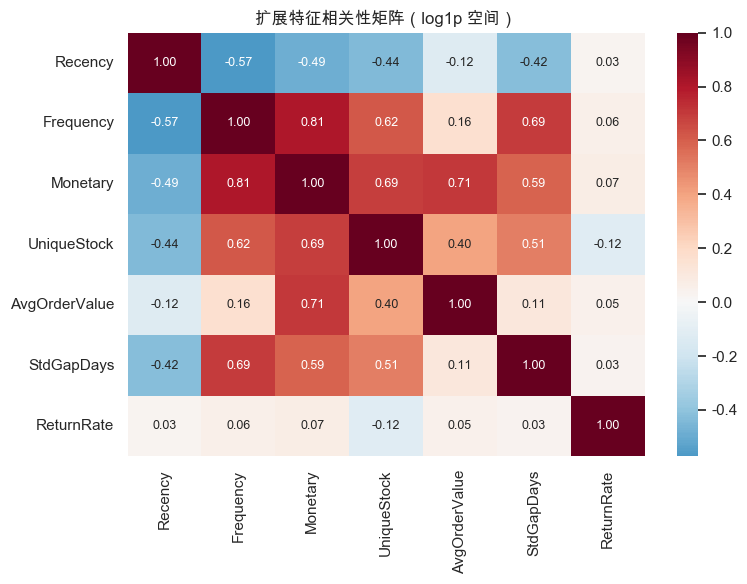

关键相关系数:
  Frequency × Monetary    = 0.808  (强正相关，预期内)
  Frequency × UniqueStock = 0.623  (买得勤 → 品类多)
  Monetary × AvgOrderValue= 0.709  (花得多 → 客单价高)


In [5]:
BASE = ["Recency", "Frequency", "Monetary"]
EXT = ["Recency", "Frequency", "Monetary", "UniqueStock", "AvgOrderValue", "StdGapDays", "ReturnRate"]

# 长尾特征统一 log1p + 标准化（与 analysis.ipynb 一致）
X_base = StandardScaler().fit_transform(np.log1p(feat[BASE]))
X_ext = StandardScaler().fit_transform(np.log1p(feat[EXT]))

# 相关性矩阵（log1p 空间）
corr = np.log1p(feat[EXT]).corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            annot_kws={"size": 9}, ax=ax)
ax.set_title("扩展特征相关性矩阵（log1p 空间）")
plt.tight_layout()
plt.show()

print("关键相关系数:")
print(f"  Frequency × Monetary    = {corr.loc['Frequency', 'Monetary']:.3f}  (强正相关，预期内)")
print(f"  Frequency × UniqueStock = {corr.loc['Frequency', 'UniqueStock']:.3f}  (买得勤 → 品类多)")
print(f"  Monetary × AvgOrderValue= {corr.loc['Monetary', 'AvgOrderValue']:.3f}  (花得多 → 客单价高)")

## 4. 基线回顾：原始 RFM K=4（复现 analysis.ipynb）

In [6]:
def fit_km(X, k, seed=42):
    km = KMeans(n_clusters=k, random_state=seed, n_init=10)
    return km.fit(X)

def cluster_metrics(X, labels):
    return {
        "silhouette": silhouette_score(X, labels),
        "DBI": davies_bouldin_score(X, labels),
        "CH": calinski_harabasz_score(X, labels),
    }

km_base = fit_km(X_base, 4)
lb_base = km_base.labels_
m_base = cluster_metrics(X_base, lb_base)
print("基线 RFM(3维) K=4:", {k: round(v, 4) for k, v in m_base.items()})
print("簇大小:", pd.Series(lb_base).value_counts().sort_index().to_dict())

基线 RFM(3维) K=4: {'silhouette': 0.3368, 'DBI': 1.013, 'CH': 3299.8621}
簇大小: {0: 699, 1: 1635, 2: 826, 3: 1178}


## 5. 改进点 1：特征扩展效果对比

In [7]:
print("扩展特征(7维) K 扫描（2~8）:")
for k in range(2, 9):
    lb = fit_km(X_ext, k).labels_
    print(f"  K={k}: silhouette={silhouette_score(X_ext, lb):.4f}  "
          f"DBI={davies_bouldin_score(X_ext, lb):.3f}  CH={calinski_harabasz_score(X_ext, lb):,.0f}")

km_ext = fit_km(X_ext, 4)
lb_ext = km_ext.labels_
m_ext = cluster_metrics(X_ext, lb_ext)
print("\n扩展特征 K=4:", {k: round(v, 4) for k, v in m_ext.items()})
print("扩展特征簇大小:", pd.Series(lb_ext).value_counts().sort_index().to_dict())

扩展特征(7维) K 扫描（2~8）:
  K=2: silhouette=0.3674  DBI=1.122  CH=2,629
  K=3: silhouette=0.3796  DBI=1.037  CH=1,871
  K=4: silhouette=0.2759  DBI=1.184  CH=1,699
  K=5: silhouette=0.2515  DBI=1.276  CH=1,672
  K=6: silhouette=0.2351  DBI=1.307  CH=1,506
  K=7: silhouette=0.2151  DBI=1.396  CH=1,402
  K=8: silhouette=0.2038  DBI=1.359  CH=1,321

扩展特征 K=4: {'silhouette': 0.2759, 'DBI': 1.1839, 'CH': 1699.4047}
扩展特征簇大小: {0: 1067, 1: 1824, 2: 140, 3: 1307}


**解读（实测）**：扩展为 7 维后 K=4 的轮廓系数 **0.3368 → 0.2759（下降）**，但 **K=3 提升到 0.3796**。这说明：

- 轮廓系数在**不同特征维度下不完全可比**：维度变多会稀释欧氏距离，这是 0.28 的一部分来源（高维惩罚）；
- 新增特征里 `AvgOrderValue` 与 `Monetary` 相关 0.709、`UniqueStock` 与 `Frequency` 相关 0.623，**冗余信息被欧氏距离重复计入**，进一步压低指标；
- 真正有意义的信号是：**扩展后最优 K 从 4 移到 3**（0.3796 > 基线 0.3368），即更多特征让"3 群"的分界更清晰——**特征扩展的价值体现在改变了最优结构，而非原地提升 K=4 指标**。


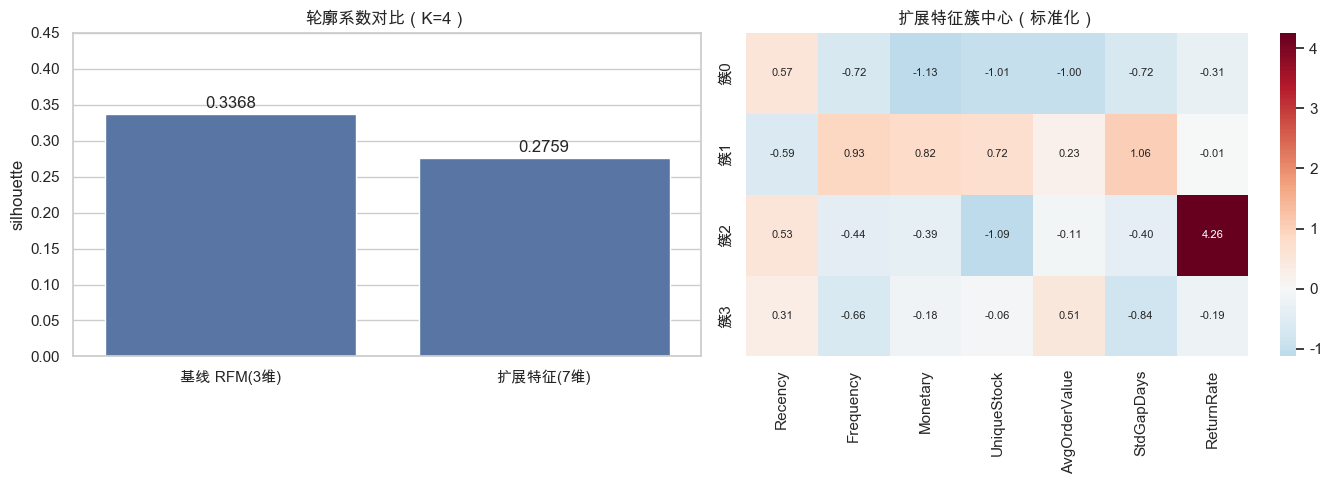

In [8]:
# 左侧：K=4 轮廓系数对比；右侧：扩展特征簇中心热力图（标准化空间）
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=["基线 RFM(3维)", "扩展特征(7维)"], y=[m_base["silhouette"], m_ext["silhouette"]], ax=axes[0])
axes[0].set_ylim(0, 0.45)
axes[0].set_ylabel("silhouette")
axes[0].set_title("轮廓系数对比（K=4）")
for i, v in enumerate([m_base["silhouette"], m_ext["silhouette"]]):
    axes[0].text(i, v + 0.008, f"{v:.4f}", ha="center")

cent = pd.DataFrame(km_ext.cluster_centers_, columns=EXT)
cent.index = [f"簇{i}" for i in range(4)]
sns.heatmap(cent, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, ax=axes[1])
axes[1].set_title("扩展特征簇中心（标准化）")
plt.tight_layout()
plt.show()

## 6. 改进点 2：Monetary Winsorize（99 分位）稳健性检验

In [9]:
# ══ Winsorize（温莎截断）稳健性检验 ══
# 目的：检验「分群结论会不会被少数极端客户绑架」。
# 做法：不是删除极端客户，而是把 Monetary 超过 99 分位的值「压」到 99 分位处。
#   clip(upper=cap) = 所有 > cap 的值一律改成 cap，其余不变 → 样本全保留，只让极端值变温和。
cap = feat["Monetary"].quantile(0.99)   # 99% 分位点：98% 的客户金额都 ≤ 它
print(f"Monetary 99 分位（截断上限）: {cap:,.2f}")
n_win = (feat["Monetary"] > cap).sum()  # 有多少客户金额超过上限（会被压下来）
print(f"被截断客户: {n_win:,} 个（{100 * n_win / len(feat):.2f}%）")
feat["Monetary_W"] = feat["Monetary"].clip(upper=cap)  # 生成截断后的新列：>cap 的变成 cap

# 用「截断后的 Monetary」重建 7 维特征矩阵并重新聚类
# 注意：Monetary_W 同样先 log1p 再标准化，与主线流程完全一致，保证可对比
EXT_W = ["Recency", "Frequency", "Monetary_W", "UniqueStock", "AvgOrderValue", "StdGapDays", "ReturnRate"]
X_win = StandardScaler().fit_transform(np.log1p(feat[EXT_W]))

km_win = fit_km(X_win, 4)      # 同样的 K=4、同样的 random_state，唯一变量是「截断」
lb_win = km_win.labels_        # Winsorize 后的簇标签
m_win = cluster_metrics(X_win, lb_win)  # 重新计算 silhouette / DBI / CH
print("扩展+Winsorize K=4:", {k: round(v, 4) for k, v in m_win.items()})
print("Winsorize 簇大小:", pd.Series(lb_win).value_counts().sort_index().to_dict())
# ARI 衡量「两次聚类给 4,338 个客户的打标有多一致」：1=完全一致，0=纯随机
# 实测 0.993 → 削平那 44 个极端客户后，几乎没人被换簇 → 结论不依赖极端值 = 稳健
print(f"\nWinsorize 前后簇标签 ARI: {adjusted_rand_score(lb_ext, lb_win):.3f}")


Monetary 99 分位（截断上限）: 19,780.49
被截断客户: 44 个（1.01%）
扩展+Winsorize K=4: {'silhouette': 0.2772, 'DBI': 1.1781, 'CH': 1718.8712}
Winsorize 簇大小: {0: 136, 1: 1064, 2: 1830, 3: 1308}

Winsorize 前后簇标签 ARI: 0.993


**这个实验在问什么？**

聚类结果会不会被少数「超级客户」带偏？全库最大单客 280,206 元、中位数才 668 元——如果这几位大佬的数据稍有变化，分群就跟着变，那结论就不可信。**稳健性检验** = 主动把极端值「削平」，再看分群结果变不变。

**Winsorize（温莎截断）是什么？**

把超过 99 分位（实测 19,780.49 元）的客户金额**一律压到 19,780.49**（`clip` 截断），而不是删除。区别：

- 删除离群点：样本从 4,338 变成 4,294，少了一批客户；
- Winsorize 截断：**4,338 个客户全保留**，只是极端值变温和，只动最极端的 1.01%。

**Monetary 其实被「压缩」了两次，作用不同：**

| 处理 | 操作 | 作用 |
|---|---|---|
| ① `log1p`（主线已有） | 280,206 → log1p ≈ 12.5 | 把「倍数级」差异变成「加数级」差异，保证 KMeans 欧氏距离的公平性（见 analysis 3.4c） |
| ② Winsorize（本节） | 19,780 以上的值压到 19,780 | 只动最极端 1%，进一步防止个别值主导 |

**结果解读（实测）**：

| 指标 | 前 | 后 | 说明 |
|---|---|---|---|
| ARI | — | **0.993** | 接近 1 = 前后打标几乎完全一致 |
| silhouette | 0.276 | 0.277 | 几乎不变 |
| 簇大小 | {136, 1064, 1830, 1308} | 同左 | 四个簇的人数和构成没变 |
| 被截断客户 | — | 44 个（1.01%） | 只动了 1% 的人 |

ARI=0.993 的含义：**把最极端的 1% 客户金额削平后，4,338 人里几乎没有一个人被换簇** → 原模型对极端值稳健，结论可信任。

**为什么会这样？** 因为 `log1p` 已把 28 万压到 ~12.5（与中位数 668→6.5 只差 6），极端客户在欧氏距离里「不显眼」了；Winsorize 是对已经温和的数据再做一次修剪，自然改变不了什么。

**结论**：若追求画像数字「干净」（如汇报表里 Monetary 不超过 2 万）可以做，但**不应期待改变任何业务结论**。本实验的价值是**证明现有 pipeline 对极端值已稳健，无需额外处理**。


In [10]:
# 画像对比：Winsorize 前后各簇中位数（Monetary 显示原始值，非截断值）
# 目的：从「簇画像」角度再确认一次——不仅指标没变，每个簇的业务数值也没变
prof_cols = BASE + ["UniqueStock", "AvgOrderValue", "StdGapDays", "ReturnRate"]
print("=== Winsorize 前（扩展特征 K=4）簇画像 ===")
print(feat.assign(cluster=lb_ext).groupby("cluster")[prof_cols].median().round(2).to_string())
print("\n=== Winsorize 后（扩展特征 K=4）簇画像 ===")
print(feat.assign(cluster=lb_win).groupby("cluster")[prof_cols].median().round(2).to_string())


=== Winsorize 前（扩展特征 K=4）簇画像 ===
         Recency  Frequency  Monetary  UniqueStock  AvgOrderValue  StdGapDays  ReturnRate
cluster                                                                                  
0         138.00       1.00    179.17        11.00         143.10        0.00        0.00
1          22.00       5.00  1,836.81        81.00         326.21       32.49        0.01
2         119.50       2.00    425.15         9.00         253.53        0.00        0.26
3          74.00       1.00    544.08        31.00         366.23        0.00        0.00

=== Winsorize 后（扩展特征 K=4）簇画像 ===
         Recency  Frequency  Monetary  UniqueStock  AvgOrderValue  StdGapDays  ReturnRate
cluster                                                                                  
0         124.50       1.50    415.64         9.00         251.01        0.00        0.26
1         138.00       1.00    179.05        11.00         142.93        0.00        0.00
2          22.00       5.00  1,83

## 7. 改进点 3：K=3/4/5/6 画像与业务解释力对比

In [11]:
prof_cols = BASE + ["UniqueStock", "AvgOrderValue", "StdGapDays", "ReturnRate"]  # 7 维全看：KMeans 在 7 维分群，只看 RFM 会误判（如 K=3 的簇 2 = 高退货簇）
print("基于扩展特征 K=3/4/5/6 的簇画像（7 维中位数）:")
for k in [3, 4, 5, 6]:
    lb = fit_km(X_ext, k).labels_
    sil = silhouette_score(X_ext, lb)
    sizes = pd.Series(lb).value_counts().sort_index()
    prof = feat.assign(c=lb).groupby("c")[prof_cols].median().round(2)
    print(f"\n--- K={k} | silhouette={sil:.4f} | 簇大小={sizes.to_dict()} ---")
    print(prof.to_string())


基于扩展特征 K=3/4/5/6 的簇画像（7 维中位数）:

--- K=3 | silhouette=0.3796 | 簇大小={0: 2313, 1: 1880, 2: 145} ---
   Recency  Frequency  Monetary  UniqueStock  AvgOrderValue  StdGapDays  ReturnRate
c                                                                                  
0    92.00       1.00    330.03        20.00         242.16        0.00        0.00
1    22.00       5.00  1,838.73        82.00         335.06       31.58        0.01
2   122.00       2.00    422.60         9.00         253.03        0.00        0.25

--- K=4 | silhouette=0.2759 | 簇大小={0: 1067, 1: 1824, 2: 140, 3: 1307} ---
   Recency  Frequency  Monetary  UniqueStock  AvgOrderValue  StdGapDays  ReturnRate
c                                                                                  
0   138.00       1.00    179.17        11.00         143.10        0.00        0.00
1    22.00       5.00  1,836.81        81.00         326.21       32.49        0.01
2   119.50       2.00    425.15         9.00         253.53        0.00 

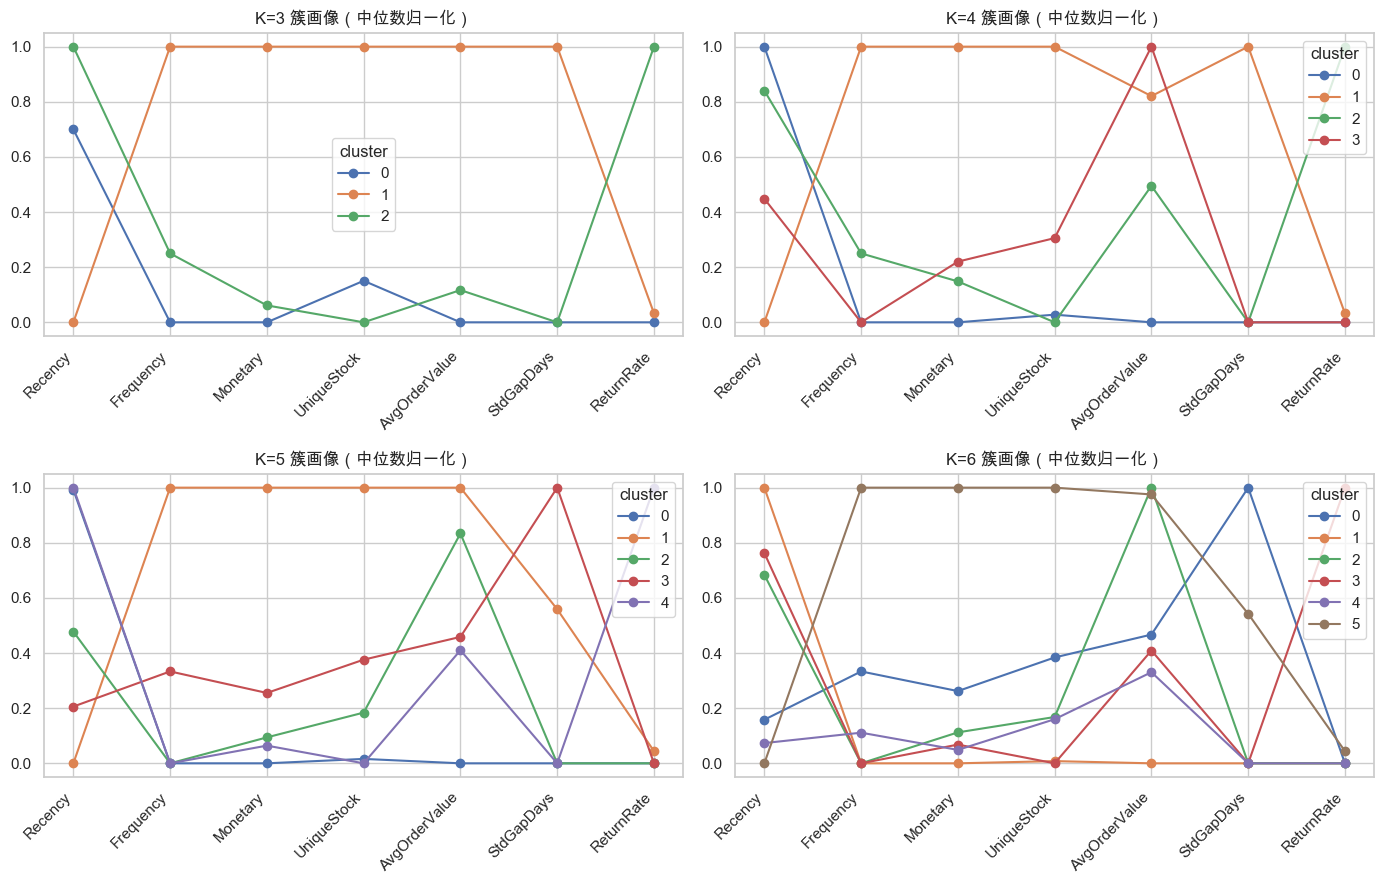

In [12]:
# 簇画像折线图（7 维中位数归一化到 0~1，便于跨 K 对比；含退货率等新特征，避免只看 RFM 误判）
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, k in zip(axes.ravel(), [3, 4, 5, 6]):
    lb = fit_km(X_ext, k).labels_
    prof = feat.assign(c=lb).groupby("c")[prof_cols].median()
    norm = (prof - prof.min()) / (prof.max() - prof.min() + 1e-9)
    norm.T.plot(ax=ax, marker="o")
    ax.set_title(f"K={k} 簇画像（中位数归一化）")
    ax.set_xticks(range(len(prof_cols)))
    ax.set_xticklabels(prof_cols, rotation=45, ha="right")
    ax.legend(title="cluster")
plt.tight_layout()
plt.show()


**解读（实测）**：

| K | silhouette | 簇大小 | 业务解读 |
|---|---|---|---|
| 3 | **0.3796** | 2313 / 1880 / 145 | 沉睡低频 / **活跃高价值**(22天·5单·1839元) / **高退货簇**(145人全员退过货，退货率中位数0.25) |
| 4 | 0.2759 | 1067 / 1824 / 140 / 1307 | 中间层被拆成两个（140 人高退货簇仍存在） |
| 5 | 0.2515 | 1002/711/1301/1213/111 | 额外分出**顶级客户**(8天·10单·3963元) |
| 6 | 0.2351 | 6 簇 | 继续细分，性价比递减 |

**注意（实测）**：KMeans 是在 **7 维空间**分群的，画像必须看 7 维中位数，**只看 RFM 三维会误判**。典型例子是 K=3 的簇 0（92天·1单·330元）与簇 2（122天·2单·423元）：RFM 三维下两簇中心仅差 0.36（标准化距离），看似"难以区分"；但簇 2 的 145 个客户 **100% 都退过货**（退得最少的客户也退了 14% 的行，如 7 行退 1 行），退货率中位数 0.25（一半客户退掉的行 ≥ 25%，均值 0.30 是被个别退 94% 的人拉高的）；簇 0 则只有 13.6% 的人退过货——7 维距离 **4.51**，是 RFM 视角的 12 倍。**簇 2 是「高退货风险客户」，不是沉睡/普通客户**；它正是特征扩展才发现的群体，也是 K=3 的第三个业务档位。

**业务判断**：K=3 指标最优且"沉睡低频 / 活跃高价值 / 高退货"三档清晰；K=5 能单独识别顶级客户（可做 VIP 运营），但两个小簇（~2.6%）解释力弱。**没有明显赢家**——若追求指标选 K=3，若关注 VIP 运营可看 K=5，K=4 相对居中。这也印证了 11.8 中"K 的选择本质是业务取舍"。


## 8. 改进点 4：RFM 经典 5 档分箱交叉验证

In [13]:
# ══ RFM 经典 5 档分箱（业务规则法：营销领域的「行业老办法」，用来交叉检验 K-means）══
# 思路：把 R/F/M 三个维度各切成 5 档（尽量等频），组合成最多 5×5×5=125 种「评分」，
#       作为客户分档的行业标准答案，再和 K-means 的簇对比是否说得通。
rfm2 = rfm.copy()
# R 档：Recency 越小（越近买过）分越高 → 标签反着排 [5,4,3,2,1]。
#   原因：qcut 的箱子按值升序排列，第一箱 = Recency 最小 = 最近（好）→ 给 5 分；
#         第五箱 = 最久远（差）→ 给 1 分。
rfm2["R_grp"] = pd.qcut(rfm2["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
# F/M 档：值越大分越高 → 标签正着排 [1,2,3,4,5]。
# 为什么 F/M 必须先 rank？qcut 要求每箱人数尽量相等，但 Frequency 有大量重复值：
#   实测 1,493 人（34%）都是 1 单——直接 qcut 会报错
#   「Bin edges must be unique」；rank(method="first") 给并列值按出现顺序编号，
#   让 4,338 个值彼此不同，qcut 才能等分（每档约 868 人）。
rfm2["F_grp"] = pd.qcut(rfm2["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm2["M_grp"] = pd.qcut(rfm2["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
# RFM_score = 三位编码 R·F·M：555 = 最佳（近+多+富）、111 = 最差（远+少+穷）。
#   理论 125 种组合，实测出现 117 种（部分组合没有客户）；555 有 347 人、111 有 182 人。
rfm2["RFM_score"] = rfm2["R_grp"] * 100 + rfm2["F_grp"] * 10 + rfm2["M_grp"]
rfm2["RFM_sum"] = rfm2["R_grp"] + rfm2["F_grp"] + rfm2["M_grp"]   # 3~15 简化总分，用于交叉表
rfm2["cluster"] = lb_ext
print(rfm2[["R_grp", "F_grp", "M_grp", "RFM_score"]].describe().T[["min", "max", "mean"]].to_string())


             min    max   mean
R_grp       1.00   5.00   3.01
F_grp       1.00   5.00   3.00
M_grp       1.00   5.00   3.00
RFM_score 111.00 555.00 333.65


ARI(K-means vs RFM 分档): 0.067
NMI(K-means vs RFM 分档): 0.300

每簇 RFM 档位与原始值中位数:
         R_grp  F_grp  M_grp  Recency  Frequency  Monetary
cluster                                                   
0         2.00   2.00   1.00   138.00       1.00    179.20
1         4.00   4.00   4.00    22.00       5.00  1,836.80
2         2.00   2.00   2.00   119.50       2.00    425.20
3         2.00   2.00   3.00    74.00       1.00    544.10

每簇 RFM_sum 中位数（越大越优质）:
cluster
0    5.00
1   13.00
2    7.00
3    7.00


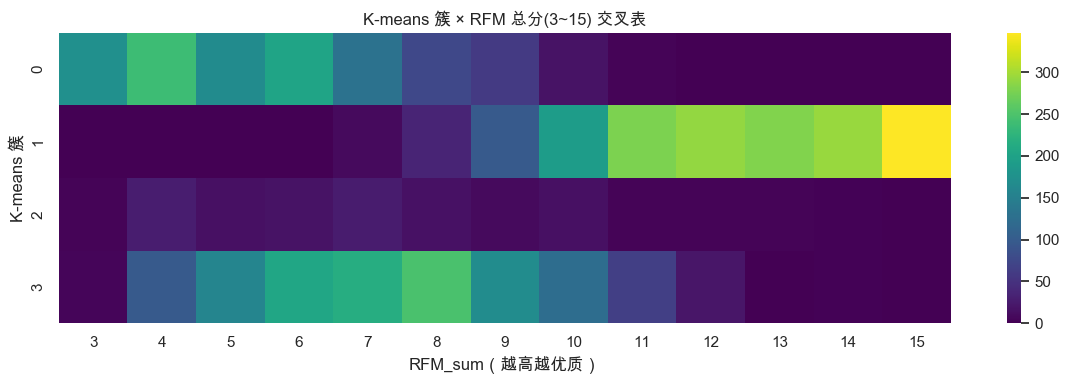

In [14]:
# ══ 交叉验证：K-means 的划分 vs RFM 经典分档，一致吗？══
# ARI / NMI：衡量「两种方法给 4,338 人打标」有多一致，1=完全一致，0=随机水平。
#   注意：比较对象粒度悬殊——K-means 只有 4 个簇，RFM_score 有 117 种组合，
#   数值天然很低（ARI=0.067 / NMI=0.300），必须结合业务自洽性一起看（见下方解读 cell）。
print(f"ARI(K-means vs RFM 分档): {adjusted_rand_score(rfm2['cluster'], rfm2['RFM_score']):.3f}")
print(f"NMI(K-means vs RFM 分档): {normalized_mutual_info_score(rfm2['cluster'], rfm2['RFM_score']):.3f}")

# 每簇 RFM 档位中位数 → 给每簇贴业务标签。
# 例：簇1 = R4/F4/M4（近 22 天、5 单、1,837 元）→ 高价值活跃；簇0 = R2/F2/M1 → 沉睡低价值。
tab = rfm2.groupby("cluster")[["R_grp", "F_grp", "M_grp", "Recency", "Frequency", "Monetary"]].agg("median").round(1)
print("\n每簇 RFM 档位与原始值中位数:")
print(tab.to_string())

# 每簇 RFM_sum（R+F+M）中位数：解读里的「簇1=13 / 簇0=5 / 簇2、3=7」来自这里，不是靠档位相加。
# 注意「中位数不可加」：簇1 的 R4+F4+M4 相加 = 12，但 RFM_sum 列的中位数 = 13——
#   因为「三列各自取中间值再相加」≠「每行先求和再取中间值」，所以别拿档位相加冒充。
print("\n每簇 RFM_sum 中位数（越大越优质）:")
print(rfm2.groupby("cluster")["RFM_sum"].median().to_string())

# 交叉表热力图：x 轴 RFM_sum（3~15，越大越优质），y 轴 K-means 簇。
#   格子的值 = 该簇落在该 sum 档的人数；颜色深浅 = 人数多少（viridis：深紫=0 → 亮黄=最多）。
#   右侧 colorbar 就是人数刻度：0~300 表示从深紫到亮黄对应 0 到约 300 人；
#   实际最多的一格有 347 人（簇1 × sum=15），matplotlib 自动把刻度取整标到 300。
#   若两种方法「序关系一致」，优质簇应集中在右侧（高 sum）、沉睡簇集中在左侧（低 sum）。
ct = pd.crosstab(rfm2["cluster"], rfm2["RFM_sum"])
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(ct, cmap="viridis", ax=ax)
ax.set_title("K-means 簇 × RFM 总分(3~15) 交叉表")
ax.set_xlabel("RFM_sum（越高越优质）")
ax.set_ylabel("K-means 簇")
plt.tight_layout()
plt.show()


**解读（实测）**：ARI=0.067 / NMI=0.300 **数值很低**，但要正确归因：

- **为什么低（1）——粒度差异**：RFM_score 实际有 117 种取值（理论 125），K-means 只有 4 簇，粒度差约 30 倍。ARI 把「拿 4 个簇去对齐 117 个细档」判为高度不一致，**ARI 不适合直接比较"4 簇 vs 125 档"**；
- **为什么低（2）——分档丢了距离**：5 档只保留"高/中/低"的次序，丢失了连续距离（1 单与 5 单只隔 4 档，但在对数空间距离更大）。结论里说的"中间细节"具体指三层：
- **中间细节 ① 档内差异被抹平**：qcut 等频分档每档约 868 人，同档客户原始值天差地别，分档后全变成同一数字。例：簇0 与簇2 档位几乎一样（R2/F2 和 R2/F2/M2），但原始值差一倍——Frequency 1 单 vs 2 单、Monetary 179 元 vs 425 元，这些差异在档位里全部消失，K-means 在连续空间却能感知；
- **中间细节 ② 档间只有次序、没有"差多少"**：Monetary 从 3.75 到 280,206 元（极右偏），log1p 后 K-means 能感知"100 元 vs 1,000 元"是 10 倍差距，档位只知道"你是 M=4 他是 M=5"；
- **中间细节 ③ 分档看不到的维度**：RFM 5 档只用 R/F/M 3 维，K-means 是 7 维。簇2 vs 簇3 在 RFM 档位上几乎一样（R2/F2/M2 vs R2/F2/M3），是靠 StdGapDays / ReturnRate 这些分档里不存在的扩展特征分开的；
- **看业务自洽性更合理**：上方「每簇 RFM_sum 中位数」输出呈单调——簇1=13、簇0=5、簇2/3=7，序关系完全一致：簇1 中位档位 **R4/F4/M4**（近 22 天、5 单、1,837 元）= **高价值活跃客户**；簇0 = **R2/F2/M1**（138 天、1 单、179 元）= **沉睡低价值客户**；簇2/3 居中。注意 **13 不是 4+4+4 加出来的**（那是 12）——它是每个客户先算 R+F+M 再取整簇中位数（中位数不可加）；
- **怎么读交叉表/colorbar**：热力图每个格子 = 该簇里 RFM_sum 等于某档的人数，颜色越亮人越多（viridis：深紫=0 → 亮黄=最多）。右侧 **colorbar 0~300 是人数刻度**（最深色实为 347 人，刻度自动取整）。看颜色重心在左还是右：簇1 的亮格几乎全在右侧（sum≥10，最亮一格 347 人），簇0 的亮格几乎全在左侧（sum≤6，最亮一格 238 人）——序关系与数值完全呼应；
- 结论：RFM 经典分档在**序关系**上与 K-means 一致（优质↔优质、沉睡↔沉睡），但 K-means 用连续距离、能保留分档丢失的中间细节，二者**不宜互相替代，互为校验**——聚类结果经得起"行业老办法"的检验。


## 9. 改进点 5 · 下：PCA 降维对比


In [15]:
# 保留 95% 方差的 PCA
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_ext)
print(f"PCA 保留主成分数: {pca.n_components_} | 累计解释方差: {pca.explained_variance_ratio_.sum():.3f}")
print("各主成分解释方差:", [round(v, 4) for v in pca.explained_variance_ratio_])

km_pca = fit_km(X_pca, 4)
lb_pca = km_pca.labels_
m_pca = cluster_metrics(X_pca, lb_pca)
print("扩展+PCA(95%) K=4:", {k: round(v, 4) for k, v in m_pca.items()})
# 三个轮廓系数集中打印，方便对比，不用回翻前面的 cell
print(f"轮廓系数对比 K=4: 基线RFM(3维)={m_base['silhouette']:.4f} | 扩展(7维)={m_ext['silhouette']:.4f} | 扩展+PCA(95%)={m_pca['silhouette']:.4f}")
print("PCA 簇大小:", pd.Series(lb_pca).value_counts().sort_index().to_dict())
print(f"PCA 后 vs 扩展特征标签 ARI: {adjusted_rand_score(lb_ext, lb_pca):.3f}")

PCA 保留主成分数: 5 | 累计解释方差: 0.957
各主成分解释方差: [np.float64(0.5084), np.float64(0.1615), np.float64(0.1475), np.float64(0.085), np.float64(0.0546)]
扩展+PCA(95%) K=4: {'silhouette': 0.2958, 'DBI': 1.1491, 'CH': 1861.9292}
轮廓系数对比 K=4: 基线RFM(3维)=0.3368 | 扩展(7维)=0.2759 | 扩展+PCA(95%)=0.2958
PCA 簇大小: {0: 1821, 1: 141, 2: 1308, 3: 1068}
PCA 后 vs 扩展特征标签 ARI: 0.990


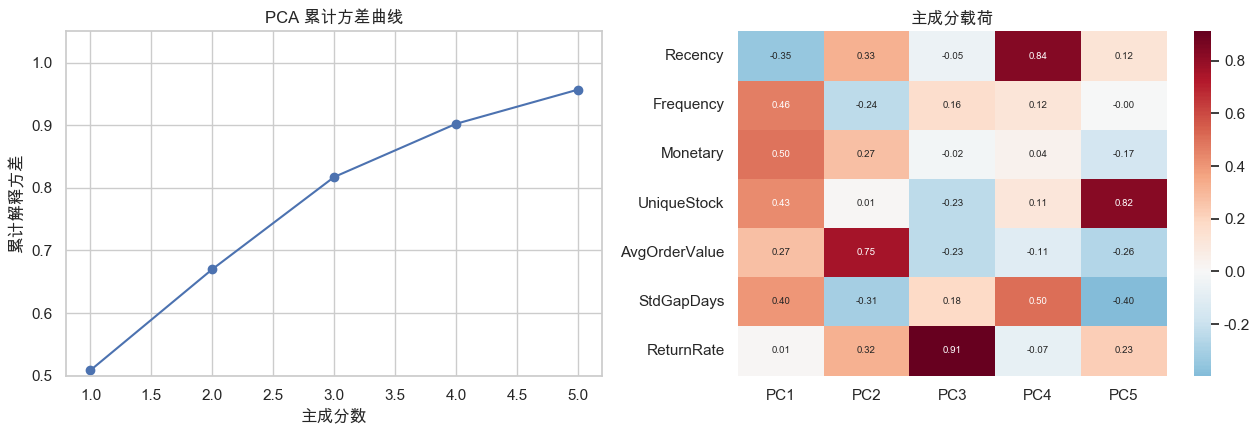

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(range(1, len(pca.explained_variance_ratio_) + 1),
        pca.explained_variance_ratio_.cumsum(), "o-")
ax.set_xlabel("主成分数"); ax.set_ylabel("累计解释方差")
ax.set_title("PCA 累计方差曲线"); ax.set_ylim(0.5, 1.05)

load = pd.DataFrame(pca.components_.T, index=EXT,
                    columns=[f"PC{i+1}" for i in range(pca.n_components_)])
sns.heatmap(load, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("主成分载荷")
plt.tight_layout()
plt.show()

**解读（实测）**：5 个主成分保留 **95.7%** 方差，K=4 轮廓系数对比——基线 RFM(3维) **0.3368** → 扩展特征(7维) **0.2759** → 扩展+PCA(95%) **0.2958**（介于两者之间，见上方对比行）：降维去掉部分冗余后指标小幅回升，但仍低于基线；且与扩展特征直接聚类的标签 **ARI=0.990**——**PCA 没有改变分群实质**，只是把 7 维压缩到 5 维、微调了指标。结合第 3 节，`Frequency×Monetary` 相关 0.808 的冗余被 PCA 部分消除，但对结果影响很小。

**结论**：PCA 类去相关手段在本数据上是"锦上添花"，不会改变业务结论；更大的价值是用 **PC1~PC2 散点做可视化**（保留 ~67% 方差）辅助展示分群。


## 10. 综合对比与结论

In [17]:
rows = []
for name, X, lb in [
    ("基线 RFM(3维)", X_base, lb_base),
    ("扩展特征(7维)", X_ext, lb_ext),
    ("扩展+Winsorize", X_win, lb_win),
    ("扩展+PCA(95%)", X_pca, lb_pca),
]:
    m = cluster_metrics(X, lb)
    sizes = pd.Series(lb).value_counts().sort_index()
    rows.append({
        "方案": name, "K": 4,
        "silhouette": round(m["silhouette"], 4),
        "DBI": round(m["DBI"], 3),
        "CH": round(m["CH"], 1),
        "min簇占比%": round(100 * sizes.min() / len(lb), 1),
        "max簇占比%": round(100 * sizes.max() / len(lb), 1),
    })
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))


          方案  K  silhouette  DBI       CH  min簇占比%  max簇占比%
  基线 RFM(3维)  4        0.34 1.01 3,299.90    16.10    37.70
    扩展特征(7维)  4        0.28 1.18 1,699.40     3.20    42.00
扩展+Winsorize  4        0.28 1.18 1,718.90     3.10    42.20
 扩展+PCA(95%)  4        0.30 1.15 1,861.90     3.30    42.00


### 结论（全部基于本 notebook 实测）

> **全局主线**：优化以**特征扩展**为核心（唯一实质性改变分群结构的改进）；其余四项均为围绕它的验证与辅助——极端值=稳健性验证、K 取舍=业务决策、业务验证=用 RFM 校验扩展簇、PCA=诊断/可视化。

1. **特征扩展（核心改进）**：扩展后最优 K 从 4 移到 **3**（轮廓 0.3796 > 基线 0.3368），但 K=4 原地指标下降（0.276）。扩展的价值是**改变/明确了最优结构**，而非提升 K=4；新特征存在冗余（F×M 相关 0.808），后续可考虑先 PCA 再聚类。
2. **极端值（稳健性验证，基于扩展特征）**：Winsorize 前后 **ARI=0.993**，分群几乎不变——`log1p` 已充分压制极端值，**原模型稳健，无需强制 Winsorize**。
3. **K 取舍（业务决策，基于扩展特征）**：K=3 指标最优、三档画像最清晰；K=5 能识别顶级客户（8 天·10 单·3,963 元）适合 VIP 运营。**按业务目标选 K**。
4. **业务验证（交叉验证，用 RFM 校验扩展簇）**：K-means 簇与 RFM 经典分档**序关系一致**（簇1=R4/F4/M4 优质、簇0=R2/F2/M1 沉睡），ARI 低源于 4 簇 vs 125 档的粒度差异，**业务上说得通**。
5. **去相关（诊断/可视化，基于扩展特征）**：PCA（95% 方差、5 主成分）后分群与原来 **ARI=0.990**，属锦上添花，可用于可视化而非必需步骤（高维场景才有省训练时间的实际收益）。

**最终建议**：若希望保留与既有分析一致的结论，沿用 **RFM K=4**；若追求指标与画像简洁，可采用 **扩展特征 K=3**（沉睡 / 活跃高价值 / 中间）。两者在"高价值簇 = 近购 + 高频 + 高额"这一核心业务结论上完全一致。
